# CLIMADA 2011

## Hazard

In [5]:
import pandas as pd
import xarray as xr
from climada_petals.hazard.river_flood import RiverFlood

DPH_FILE = 'cama-flood_classic_gfdl-esm4_historical_2015soc_default_flddphmax_flopros_15arcmin_global_annual_1850_2014.nc'
FRC_FILE = 'cama-flood_classic_gfdl-esm4_historical_2015soc_default_fldfrcmax_flopros_15arcmin_global_annual_1850_2014.nc'
YEARS = [2011]   # data covers 1850-2014

# These ISIMIP3b files can't go straight into RiverFlood.from_isimip_nc:
#   - time uses a "noleap" (365_day) calendar -> pd.to_datetime fails (the TypeError we got)
#   - ocean / missing cells are stored as 1e+20 instead of NaN
#   - depth file has lat north->south, fraction file south->north
# So we write a cleaned copy containing only the years we need.
def clean_isimip3(in_file, out_file, years):
    ds = xr.open_dataset(in_file)                      # opens with cftime dates
    ds = ds.sel(time=ds.time.dt.year.isin(years))      # keep only selected years
    ds = ds.assign_coords(time=pd.to_datetime([f'{t.year}-01-01' for t in ds.time.values]))  # standard calendar
    ds = ds.where(ds < 1e19, 0)                        # 1e+20 fill values -> 0
    ds = ds.sortby('lat', ascending=False)             # north -> south, same for both files
    for v in ds.variables:                             # drop the original storage settings
        ds[v].encoding = {}
    ds.to_netcdf(out_file)

clean_isimip3(DPH_FILE, 'flddph_clean.nc', YEARS)
clean_isimip3(FRC_FILE, 'fldfrc_clean.nc', YEARS)

# Load river flood hazard from the cleaned flood depth and flooded fraction files
rf = RiverFlood.from_isimip_nc(
    dph_path='flddph_clean.nc',
    frc_path='fldfrc_clean.nc',
    countries=['THA'],          # ISO3 country code(s) to cut out of the global grid
    years=YEARS,
)
rf.check()
print(rf.size, 'events,', rf.centroids.size, 'centroids, max depth', rf.intensity.max(), 'm')

1 events, 2040 centroids, max depth 8.9403715 m


<GeoAxes: title={'center': 'RF max intensity at each point'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


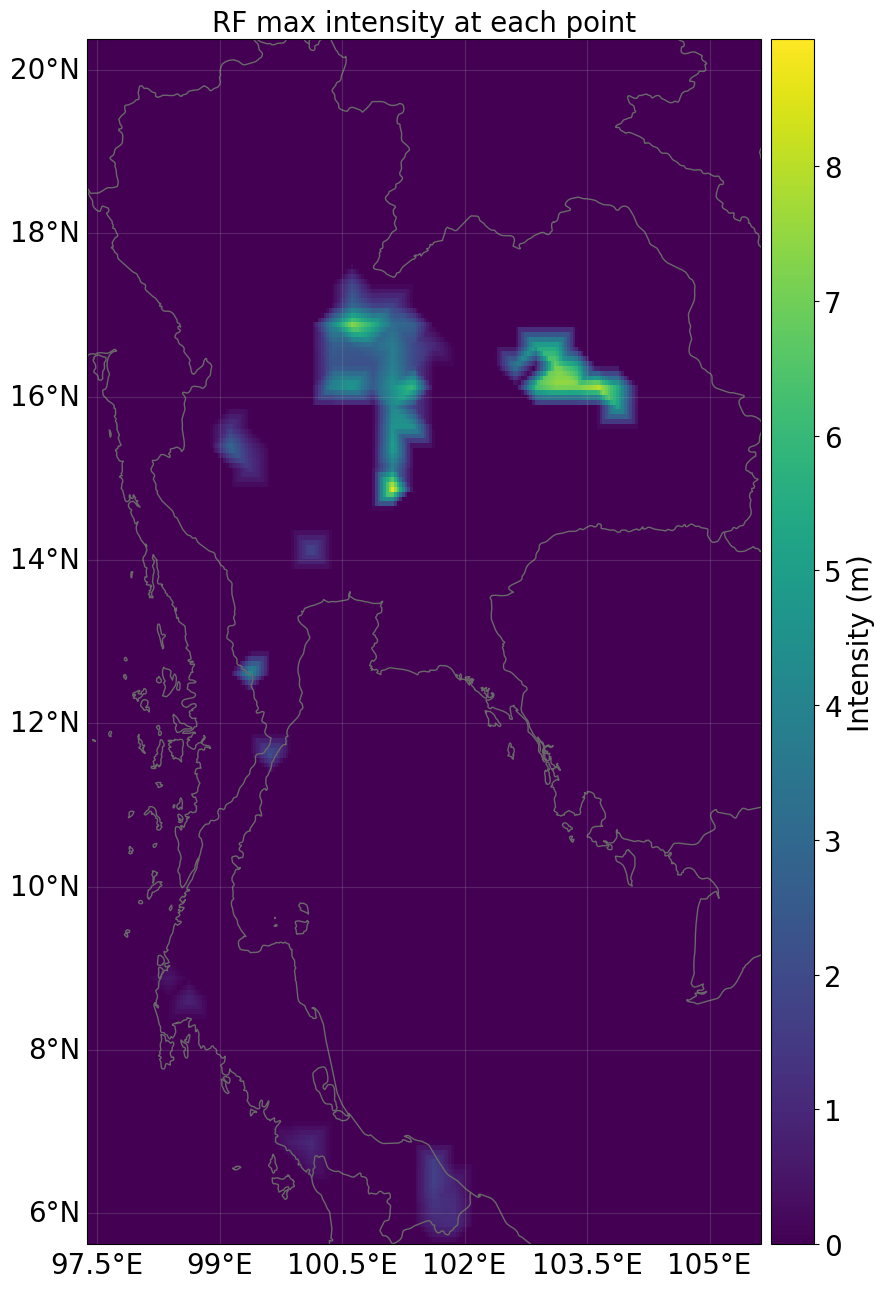

In [6]:
rf.plot_intensity(event=0)

<GeoAxes: title={'center': 'RF max intensity at each point'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


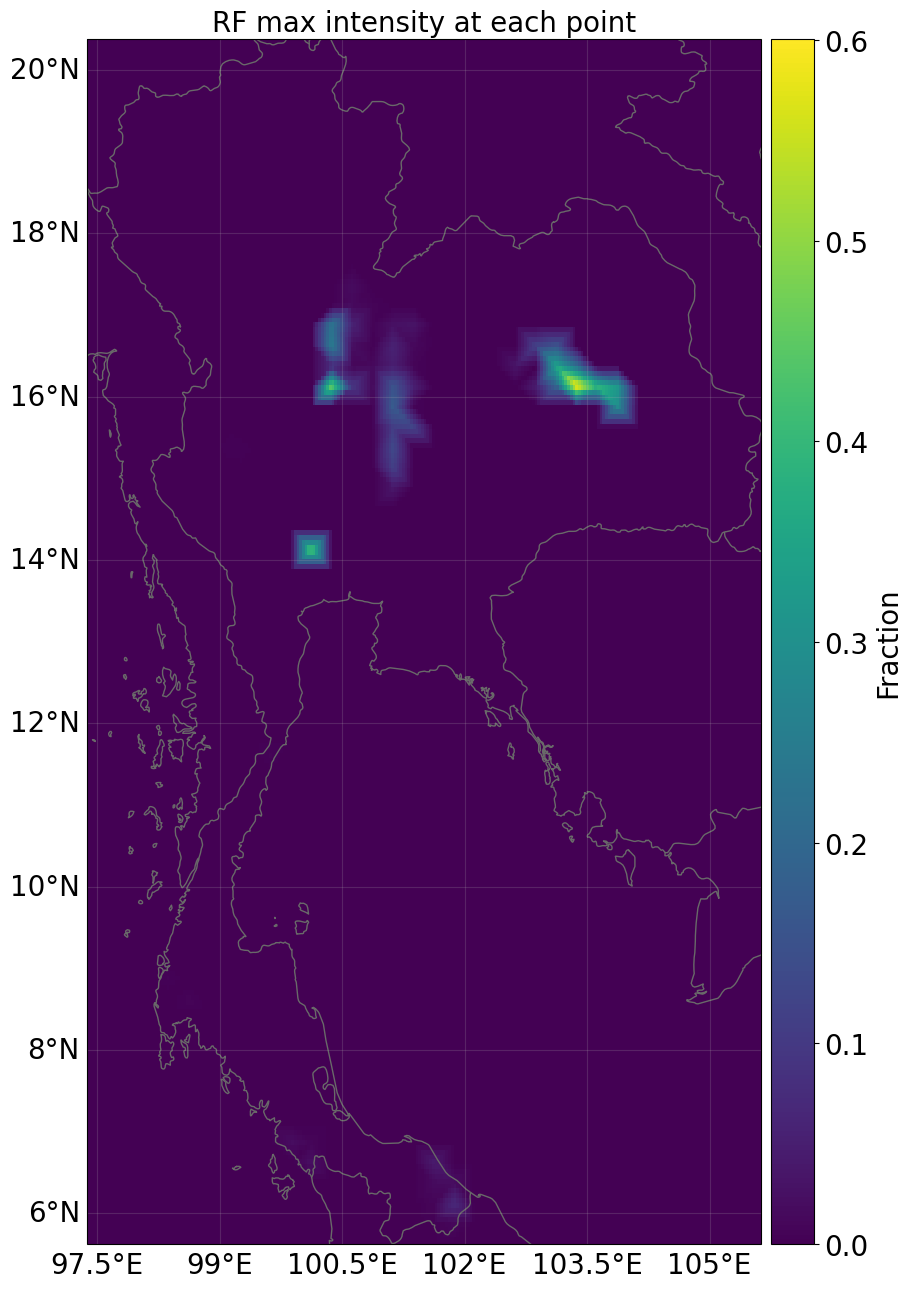

In [7]:
rf.plot_fraction(event=0)